<a href="https://colab.research.google.com/github/sanjana0422/finance/blob/main/finance_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
train_df = pd.read_csv("sent_train.csv")
val_df = pd.read_csv("sent_valid.csv")

In [ ]:
val_df

,text,label
0,$ALLY - Ally Financial pulls outlook https://t...,0
1,"$DELL $HPE - Dell, HPE targets trimmed on comp...",0
2,$PRTY - Moody's turns negative on Party City h...,0
3,$SAN: Deutsche Bank cuts to Hold,0
4,$SITC: Compass Point cuts to Sell,0
...,...,...
2383,Stocks making the biggest moves midday: TD Ame...,2
2384,Stocks making the biggest moves premarket: Fit...,2
2385,Stocks making the biggest moves premarket: Hom...,2
2386,Stocks making the biggest moves premarket: TD ...,2


In [ ]:
train_df

,text,label
0,$BYND - JPMorgan reels in expectations on Beyo...,0
1,$CCL $RCL - Nomura points to bookings weakness...,0
2,"$CX - Cemex cut at Credit Suisse, J.P. Morgan ...",0
3,$ESS: BTIG Research cuts to Neutral https://t....,0
4,$FNKO - Funko slides after Piper Jaffray PT cu...,0
...,...,...
9538,The Week's Gainers and Losers on the Stoxx Eur...,2
9539,Tupperware Brands among consumer gainers; Unil...,2
9540,vTv Therapeutics leads healthcare gainers; Myo...,2
9541,"WORK, XPO, PYX and AMKR among after hour movers",2


In [ ]:
print("Train columns:", train_df.columns)
print("Val columns:", val_df.columns)

Train columns: Index(['text', 'label'], dtype='object')
Val columns: Index(['text', 'label'], dtype='object')


In [ ]:
print("Train shape:", train_df.shape)
print("Val shape:", val_df.shape)

Train shape: (9543, 2)
Val shape: (2388, 2)


In [ ]:
label_map = {0: 'Bearish', 1: 'Bullish', 2: 'Neutral'}
train_df['sentiment'] = train_df['label'].map(label_map)
val_df['sentiment'] = val_df['label'].map(label_map)
print("\nTrain Class Distribution:")
print(train_df['sentiment'].value_counts())


Train Class Distribution:
sentiment
Neutral    6178
Bullish    1923
Bearish    1442
Name: count, dtype: int64


In [ ]:
print("\nVal Class Distribution:")
print(val_df['sentiment'].value_counts())


Val Class Distribution:
sentiment
Neutral    1566
Bullish     475
Bearish     347
Name: count, dtype: int64


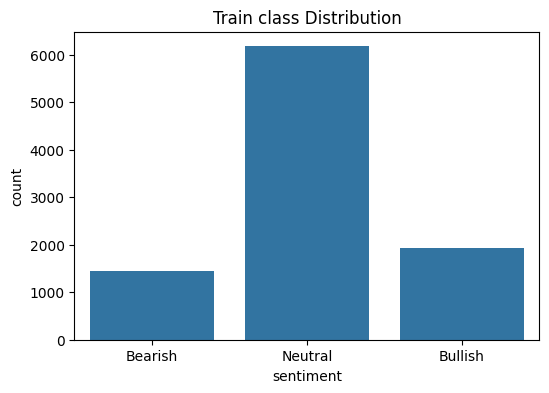

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x='sentiment',order=['Bearish','Neutral','Bullish'])
plt.title('Train class Distribution')
plt.savefig('train_class_distribution.png')
plt.show()

In [ ]:
total=len(train_df)
for k,v in train_df['sentiment'].value_counts().items():
   per=(v/total)*100
   print(k,v,per)

Neutral 6178 64.73855181808655
Bullish 1923 20.150895944671486
Bearish 1442 15.110552237241958


In [ ]:
import re
def clean_text(text):
    text =str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text=re.sub(r'@\W+', ' ', text)
    text = re.sub(r'\s+[a-zA-Z0-9$]\s+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

In [ ]:
train_df['clean_text']=train_df['text'].apply(clean_text)
val_df['clean_text']=val_df['text'].apply(clean_text)


In [ ]:
print(train_df[['text','clean_text']])

                                                   text  \
0     $BYND - JPMorgan reels in expectations on Beyo...   
1     $CCL $RCL - Nomura points to bookings weakness...   
2     $CX - Cemex cut at Credit Suisse, J.P. Morgan ...   
3     $ESS: BTIG Research cuts to Neutral https://t....   
4     $FNKO - Funko slides after Piper Jaffray PT cu...   
...                                                 ...   
9538  The Week's Gainers and Losers on the Stoxx Eur...   
9539  Tupperware Brands among consumer gainers; Unil...   
9540  vTv Therapeutics leads healthcare gainers; Myo...   
9541    WORK, XPO, PYX and AMKR among after hour movers   
9542             YNDX, I, QD and OESX among tech movers   

                                             clean_text  
0     $bynd - jpmorgan reels in expectations on beyo...  
1     $ccl $rcl - nomura points to bookings weakness...  
2     $cx - cemex cut at credit suisse, j.p. morgan ...  
3                   $ess: btig research cuts to neutral  
4

In [ ]:
print(val_df[['text','clean_text']])

                                                   text  \
0     $ALLY - Ally Financial pulls outlook https://t...   
1     $DELL $HPE - Dell, HPE targets trimmed on comp...   
2     $PRTY - Moody's turns negative on Party City h...   
3                      $SAN: Deutsche Bank cuts to Hold   
4                     $SITC: Compass Point cuts to Sell   
...                                                 ...   
2383  Stocks making the biggest moves midday: TD Ame...   
2384  Stocks making the biggest moves premarket: Fit...   
2385  Stocks making the biggest moves premarket: Hom...   
2386  Stocks making the biggest moves premarket: TD ...   
2387         TCO, NNVC, GPOR and JE among midday movers   

                                             clean_text  
0                  $ally - ally financial pulls outlook  
1     $dell $hpe - dell, hpe targets trimmed on comp...  
2          $prty - moody's turns negative on party city  
3                      $san: deutsche bank cuts to hold  
4

In [ ]:
train_df.to_csv('train_clean.csv', index=False)
val_df.to_csv('val_clean.csv', index=False)
print("\n saved:train_clean.csv")
print("\n saved:val_clean.csv")


 saved:train_clean.csv

 saved:val_clean.csv


In [ ]:
#lstm model
import pandas as pd
df=pd.read_csv('train_clean.csv')
df.head()
print(df['label'].unique())

[0 1 2]


In [ ]:
x=df['clean_text']
y=df['label']
#print("NaN in y:",y.isna().sum())
print("X shape:",x.shape)
print("label distribution:\n",y.value_counts())

X shape: (9543,)
label distribution:
 label
2    6178
1    1923
0    1442
Name: count, dtype: int64


In [ ]:
#tain/split test
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
print("x_train shape:",x_train.shape)
print("x_test shape:",x_test.shape)
print("y_train shape:",y_train.shape)
print("y_test shape:",y_test.shape)

x_train shape: (7634,)
x_test shape: (1909,)
y_train shape: (7634,)
y_test shape: (1909,)


In [ ]:
#tokenizing and pdding
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
tokenizer=Tokenizer(num_words=10000,oov_token='<OOV>')
x_train=x_train.fillna("").astype(str)
x_test=x_test.fillna("").astype(str)
tokenizer.fit_on_texts(x_train)
x_train_seq=tokenizer.texts_to_sequences(x_train)
x_test_seq=tokenizer.texts_to_sequences(x_test)
max_len=100
x_train_pad=pad_sequences(x_train_seq,maxlen=max_len,padding='post')
x_test_pad=pad_sequences(x_test_seq,maxlen=max_len,padding='post')

In [ ]:
#building lstm model for 3classes
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,Bidirectional,LSTM,Dense,Dropout
tf.keras.backend.clear_session()
model=Sequential([Embedding(input_dim=10000,output_dim=256,input_length=100),
Bidirectional(LSTM(64,return_sequences=True,dropout=0.4,recurrent_dropout=0.4)),
Bidirectional(LSTM(32,dropout=0.4,recurrent_dropout=0.4)),
Dense(32,activation='relu'),
Dropout(0.6),
Dense(3,activation='softmax')])
model.compile(loss='sparse_categorical_crossentropy',
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
              metrics=['accuracy'])
model.build(input_shape=(None,100))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 256)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 100, 128)       │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,767,747 (10.56 MB)

 Trainable params: 2,767,747 (10.56 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import pandas as pd
print(pd.Series(y_train).value_counts(normalize=True))
print(pd.Series(y_test).value_counts(normalize=True))

label
2    0.647367
1    0.201467
0    0.151166
Name: proportion, dtype: float64
label
2    0.647459
1    0.201676
0    0.150864
Name: proportion, dtype: float64


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping=EarlyStopping(monitor='val_accuracy',patience=2,restore_best_weights=True)
history=model.fit(x_train_pad,y_train,epochs=15,validation_data=(x_test_pad,y_test),
                  batch_size=64,callbacks=[early_stopping],verbose=1)

Epoch 1/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 51s 359ms/step - accuracy: 0.6306 - loss: 0.9528 - val_accuracy: 0.6475 - val_loss: 0.8788
Epoch 2/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 43s 361ms/step - accuracy: 0.6514 - loss: 0.8694 - val_accuracy: 0.6726 - val_loss: 0.7118
Epoch 3/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 81s 357ms/step - accuracy: 0.7228 - loss: 0.6550 - val_accuracy: 0.7412 - val_loss: 0.6477
Epoch 4/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 43s 362ms/step - accuracy: 0.7747 - loss: 0.5218 - val_accuracy: 0.7344 - val_loss: 0.6881
Epoch 5/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 42s 350ms/step - accuracy: 0.7994 - loss: 0.4526 - val_accuracy: 0.7428 - val_loss: 0.7672
Epoch 6/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 355ms/step - accuracy: 0.8149 - loss: 0.4029 - val_accuracy: 0.7334 - val_loss: 0.8306
Epoch 7/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 42s 351ms/step - accuracy: 0.8241 - loss: 0.3737 - val_accuracy: 0.7255 - val_loss: 0.8467


In [ ]:
model.save('lstm_model.h5')
print("model saved")

model saved


In [ ]:
loss,acc=model.evaluate(x_test_pad,y_test)
print("loss:",loss)
print("acc:",acc)

60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.7428 - loss: 0.7672
loss: 0.7671985626220703
acc: 0.7427972555160522


60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step
              precision    recall  f1-score   support

     Bearish       0.40      0.03      0.06       288
     Bullish       0.51      0.68      0.58       385
     Neutral       0.84      0.93      0.88      1236

    accuracy                           0.74      1909
   macro avg       0.58      0.55      0.51      1909
weighted avg       0.71      0.74      0.70      1909



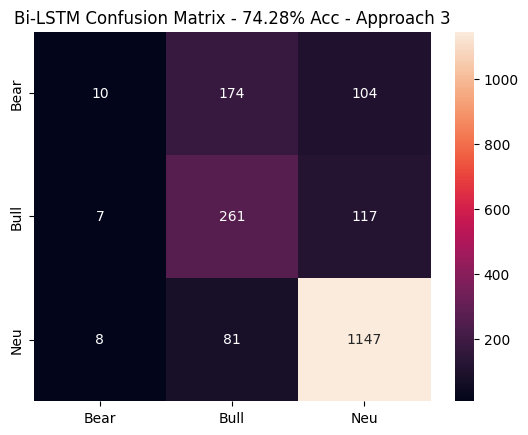

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

y_pred_prob = model.predict(x_test_pad)
y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(y_test, y_pred, target_names=['Bearish','Bullish','Neutral']))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=['Bear','Bull','Neu'], yticklabels=['Bear','Bull','Neu'])
plt.title("Bi-LSTM Confusion Matrix - 74.28% Acc - Approach 3")
plt.savefig("confusion_matrix_final.png")
plt.show()

In [17]:
%%writefile /content/app.py
import os, pickle, pandas as pd, numpy as np
import streamlit as st
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import pad_sequences

st.set_page_config(page_title="Financial News Sentiment", layout="wide")
st.title("📈 Financial News Sentiment Dashboard - Sec 5")
st.caption("Model: Bi-LSTM (Approach 3) | Accuracy: 74.28%")

@st.cache_resource
def load_assets():
    with open("/content/tokenizer.pkl", 'rb') as f:
        tokenizer = pickle.load(f)
    model_path = "/content/lstm_model.h5" if os.path.exists("/content/lstm_model.h5") else "/content/fusion_model.h5"
    model = load_model(model_path)
    return model, tokenizer

model, tokenizer = load_assets()
labels = ["Bearish", "Bullish", "Neutral"]

# 5.b - Text box
st.subheader("5.b User Input - Tweet/Headline")
user_text = st.text_area("Type a tweet/headline:", "Market shows bullish trend, stocks set to rise", height=100)

if st.button("Predict Sentiment & Show Probabilities", type="primary"):
    seq = tokenizer.texts_to_sequences([user_text])
    pad = pad_sequences(seq, maxlen=100, padding='post')
    probs = model.predict(pad, verbose=0)[0]
    pred = labels[np.argmax(probs)]

    c1, c2 = st.columns(2)
    with c1:
        if pred == "Bullish": st.success(f"Predicted: {pred} - {max(probs)*100:.2f}%")
        elif pred == "Bearish": st.error(f"Predicted: {pred} - {max(probs)*100:.2f}%")
        else: st.info(f"Predicted: {pred} - {max(probs)*100:.2f}%")

        st.markdown("**5.c.1 Bar chart of class probabilities**")
        st.bar_chart(pd.DataFrame({"Sentiment": labels, "Prob": probs}).set_index("Sentiment"))

    with c2:
        st.markdown("**5.c.2 Overall class distribution (Train)**")
        dist = pd.DataFrame({"Sentiment": ["Neutral","Bullish","Bearish"], "Count": [6178,1923,1442]})
        st.bar_chart(dist.set_index("Sentiment"))
        st.caption("Source: train_clean.csv - 9543 samples")

Overwriting /content/app.py


In [ ]:
import pickle, pandas as pd
from tensorflow.keras.preprocessing.text import Tokenizer

# Use your actual file
df = pd.read_csv("/content/train_clean.csv")
print(df.columns.tolist())

# Auto-detect text column
text_col = 'clean_text' if 'clean_text' in df.columns else df.columns[0]
print(f"Using column: {text_col}")

tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(df[text_col].astype(str).tolist())

with open("/content/tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("✅ DONE! Created /content/tokenizer.pkl")
!ls -lh /content/*.pkl /content/*.h5

['text', 'label', 'sentiment', 'clean_text']
Using column: clean_text
✅ DONE! Created /content/tokenizer.pkl
-rw-r--r-- 1 root root  32M Nov  3 10:08 /content/lstm_model.h5
-rw-r--r-- 1 root root 666K Nov  3 10:31 /content/tokenizer.pkl


In [18]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501, height=800)
import os, threading
def run():
  os.system('streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true --server.enableCORS false --server.enableXsrfProtection false')
threading.Thread(target=run, daemon=True).start()

<IPython.core.display.Javascript object>